In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
rng = np.random.default_rng(42)

n = 300

study = rng.integers(10, 121, n)
screen = rng.integers(10, 151, n)
sleep = np.round(rng.uniform(3, 10, n), 1)
concentration = rng.integers(1, 11, n)
tasks = rng.integers(0, 8, n)

# Create sample labels using simple rules
labels = (
    (study >= 60) |
    (screen >= 90) |
    (sleep < 5.5) |
    (concentration <= 4)
).astype(int)

# Add a little noise to make the sample more realistic
flip = rng.choice(n, size=18, replace=False)
labels[flip] = 1 - labels[flip]

df = pd.DataFrame({
    "study_minutes": study,
    "screen_minutes": screen,
    "sleep_hours": sleep,
    "concentration": concentration,
    "tasks_completed": tasks,
    "recommendation": np.where(
        labels == 1,
        "TAKE A BREAK",
        "CONTINUE STUDYING"
    )
})

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset created successfully!
Dataset shape: (300, 6)


,study_minutes,screen_minutes,sleep_hours,concentration,tasks_completed,recommendation
0,19,61,8.5,9,4,CONTINUE STUDYING
1,95,126,3.9,5,2,TAKE A BREAK
2,82,11,6.8,10,1,CONTINUE STUDYING
3,58,136,6.6,8,2,TAKE A BREAK
4,58,86,9.0,7,4,CONTINUE STUDYING


In [3]:
X = df.drop(columns=["recommendation"])
y = df["recommendation"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed!
Training samples: 240
Testing samples: 60


In [4]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Model Accuracy: 91.67 %

Classification Report:

                   precision    recall  f1-score   support

CONTINUE STUDYING       0.80      0.50      0.62         8
     TAKE A BREAK       0.93      0.98      0.95        52

         accuracy                           0.92        60
        macro avg       0.86      0.74      0.78        60
     weighted avg       0.91      0.92      0.91        60



In [5]:
new_student = pd.DataFrame([{
    "study_minutes": 75,
    "screen_minutes": 100,
    "sleep_hours": 6.5,
    "concentration": 7,
    "tasks_completed": 3
}])

prediction = model.predict(new_student)

print("Student Study Details:")
print(new_student.to_string(index=False))

print("\nML Prediction:", prediction[0])

Student Study Details:
 study_minutes  screen_minutes  sleep_hours  concentration  tasks_completed
            75             100          6.5              7                3

ML Prediction: TAKE A BREAK


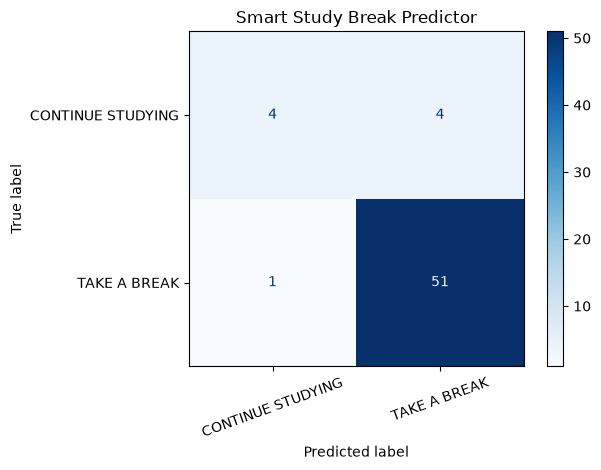

In [6]:
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    cmap="Blues",
    xticks_rotation=20
)

plt.title("Smart Study Break Predictor")
plt.tight_layout()
plt.show()